# Generator trade study

Which generative model should propose new stellarator designs? This notebook compares five ML generators with blending (mixing two passing designs, no generative model), in three stages:

1. **Offline trade study** (`scripts/seeded/gen_study.py`). Train every model type at a grid of settings (144 in all) and score ~3,000 samples from each with the screening models. No simulations.
2. **Pilot** (`scripts/seeded/gen_pilot.py`). Unscreened designs from each finalist, simulated at full accuracy: 60 each from the five first-round finalists, then 40 each from three variants tried after the first round failed. This measures the generator itself and checks the screening models' predictions.
3. **Loop runs** (`scripts/seeded/loop.py --proposer gen:<name> --screen`). Three generators (the mixture, the VAE, diffusion) each propose for the full propose → screen → simulate loop: 5 rounds of 60 simulations (300), 3 runs each. They're compared with blending's runs at the same 300-simulation budget.

| File in `results/generators/` | Shows |
|---|---|
| `architecture_trade.png` | each architecture, what was tuned, and how it performs: predicted offline, simulated in the pilot, and in the loop |
| `novelty_vs_validity.png` | every setting tried: share of new designs vs. predicted pass rate |
| `memorization.png` | each model's main knob vs. how often it copies its training designs |
| `pilot.png` | finalists: predicted vs. real pass rates, new passing designs |
| `loop_runs.png` | new passing designs, score gained and each round's pass rate vs. simulations, generators vs. blending |
| `buildability.png` | the most buildable passing design at each compactness level |
| `trade_study.json` | all numbers above |

**Metrics: the benchmark's own, as in the repo README.**
- **Feasible:** all 5 Benchmark 3 requirements within 1%, from the shared evaluator (constellaration 0.2.6, high fidelity).
- **Score:** the hypervolume over (−L∇B, aspect ratio), reference point (1, 20).
- **Cost:** evaluations (simulations) spent.

Our angle is **producibility**. L∇B is the benchmark's "simpler coils" objective, so `buildability.png` reads the same results that way: the best L∇B available at each compactness level.

**Scope:** NFP 3 at 4×4 Fourier modes (80 shape numbers), the dataset's resolution. The models train on the 8,074 public passing designs in that space; whole families are held out to test generalization. The leaderboard's best front is higher resolution (HV 285.3), and nothing here reaches it.

**Needs** the local results in `data/gen/` and `data/seeded/` (gitignored). The data cell rebuilds the training table, so run this only while no loop is running. Kernel: the `stellarator` env.

## What we found (Nov 17)

1. **Offline scores did not transfer.** The screening models predicted 59–97% pass rates for the neural generators' designs. In real simulations they passed 0–15%: VAE 15%, diffusion 2–5%, the conditional models 0%. The PCA + Gaussian mixture passed 47%, and blending 44%.
2. **The failures are a precision problem.** Nearly every failing design misses the QI limit (or the mirror ratio) by a few percent. The public passing designs are optimizer outputs that sit right at the QI limit. The neural models' errors are enough to break it: the VAE's held-out reconstruction error, ~0.005, is larger than the 0.003 novelty threshold. The screening models can't see errors that small. Less sampling noise, small diffusion edits and a lower VAE temperature didn't help.
3. **The loop partly corrects the screen, by retreating to near-copies.** In the first screened round, the VAE passed 2%, worse than its unscreened 15%: the screen picked exactly the designs it misjudged most. After retraining on those failures, it passed ~51% from round 3 on. Diffusion stayed under 11%. But the designs the loop learned to trust sit close to existing ones: median novelty ~0.004, against ~0.0065 for blending. Only 3 of the VAE's ~330 passes are ≥ 0.01 from every public design.
4. **The generators didn't move the front.** At 300 simulations, the screened generator runs added 0.00–0.06 to the score; screened blending added 0.33–0.62. The generators' passes sit inside the front (A ≈ 9–13), not at its edges.
5. **So far the ML that pays off is the screening model** (blending: 44% → ~90% passing), not the generator. A neural generator would need a repair step that pulls its designs back onto the QI limit.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "seeded").is_dir())
sys.path[:0] = [str(ROOT / "scripts" / "seeded"), str(ROOT / "scripts")]
import generators as G
import loop
import training_data
from families import NOVELTY, STRICT, load, nearest_public
from screen import TOL, load_table
from shapes import to_vector

GEN, SEEDED, OUT = ROOT / "data" / "gen", ROOT / "data" / "seeded", ROOT / "results" / "generators"
LOGS = SEEDED / "logs"
OUT.mkdir(parents=True, exist_ok=True)
SEEDS = (30, 31, 32)
ROUNDS = 5          # equal budget for every loop run: 5 rounds x 60 = 300 simulations

INK, INK2, MUTED, RULE = "#111620", "#465063", "#6f7a8c", "#dce1e9"
# one color per model family, in the reference palette's fixed slot order; blending is the gray baseline
FAM = {"vae": ("#2a78d6", "VAE"), "diff": ("#eb6834", "Diffusion"),
       "cvae": ("#1baf7a", "Conditional VAE"), "cdiff": ("#eda100", "Conditional diffusion"),
       "gmm": ("#e87ba4", "PCA + Gaussian mixture"), "blend": (MUTED, "Blending (no generative model)")}
MARK = {"prior": "o", "edit": "D", "interp": "^", "blend": "s"}
plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 10.5, "axes.labelsize": 9, "axes.labelcolor": INK2,
    "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": MUTED, "axes.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": RULE, "grid.linewidth": 0.6, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": "white",
})

## Data

Trade-study rows, the pilot's designs and simulations, and the loop runs' picks and simulations (first 5 rounds of each). A finalist is matched to its trade-study row by model settings and sampling strategy. Loop score gains are counted from the shared start: the public NFP-3 4×4 front plus the new passing designs every run starts with.

In [2]:
study = [json.loads(x) for x in (GEN / "study.jsonl").open()]
for r in study:
    r["family"] = r["config"]["model"]

designs = {d["id"]: d for d in map(json.loads, (GEN / "pilot_designs.jsonl").open())}
ledger = GEN / "runs" / "pilot.jsonl"
sims = {r["id"]: r for r in map(json.loads, ledger.open()) if r["id"] in designs} if ledger.exists() else {}


def spec_of(name):
    s = G.FINALISTS[name][1]
    return s.get("strategy", "prior"), s["temp"], s.get("guide", 0.0)


def matches(row, name):
    make, _ = G.FINALISTS[name]
    st, temp, guide = spec_of(name)
    return (row["config"] == make().config() and row["strategy"] == st and row["temp"] == temp
            and row.get("guide", 0.0) == guide)


finalist_row = {n: next((r for r in study if matches(r, n)), None) for n in G.FINALISTS}

pilot = {}
for name in G.FINALISTS:
    ds = [(d, sims[i]) for i, d in designs.items() if d["method"] == name and i in sims]
    if not ds:
        continue
    ok = [(d, r) for d, r in ds if r["ok"]]
    ps = [(d, r) for d, r in ok if r["feasible"]]
    pilot[name] = {
        "simulated": len(ds), "crashed": len(ds) - len(ok), "passed": len(ps),
        "pass_rate": len(ps) / len(ds),
        "predicted_pass_rate": float(np.mean([d["pred_pass"] * (1 - d["pred_crash"]) for d, _ in ds])),
        "strict_novel_passes": sum(d["novelty"] >= STRICT for d, _ in ps),
        "A": [r["aspect_ratio"] for _, r in ps], "L": [r["L_gradB"] for _, r in ps]}
    fails = {}
    for d, r in ok:
        if not r["feasible"]:
            k = max(r["violations"], key=r["violations"].get)
            fails[k] = fails.get(k, 0) + 1
    pilot[name]["worst_constraint_of_failures"] = dict(sorted(fails.items(), key=lambda kv: -kv[1]))
    if ps and "target_A" in ps[0][0]:
        pilot[name]["median_A_miss"] = float(np.median([abs(r["aspect_ratio"] - d["target_A"]) for d, r in ps]))
        pilot[name]["median_L_minus_asked"] = float(np.median([r["L_gradB"] - d["target_L"] for d, r in ps]))

# ---- loop runs: the shared start, then each run's first ROUNDS rounds
training_data.build()
t, pub = load_table(), load()
shared = loop.arm_view(t, "__shared_only__")
ok_sh = (shared["source"] == "ours") & ~shared["crash"] & (shared["max_violation"] <= TOL)
nov_sh = np.zeros(len(shared["X"]), bool)
nov_sh[ok_sh] = nearest_public(shared["X"][ok_sh]) >= NOVELTY
base_pp = loop.hypervolume(np.r_[pub["A"], shared["A"][nov_sh]], np.r_[pub["L"], shared["L"][nov_sh]])


def vec(p):
    b = p["boundary"]
    return to_vector(json.loads(b) if isinstance(b, str) else b)


def load_run(name):
    """One run's first ROUNDS rounds: per round, its picks with their simulation results."""
    f = LOGS / f"loop_{name}.jsonl"
    if not f.exists():
        return None
    logs = [json.loads(x) for x in f.open()][:ROUNDS]
    res = {r["id"]: r for r in map(json.loads, (SEEDED / "runs" / f"loop_{name}.jsonl").open())}
    rounds = []
    for k in range(len(logs)):
        picks = [json.loads(x) for x in (SEEDED / f"loop_{name}_r{k}.jsonl").open()]
        rounds.append([(p, res[p["id"]]) for p in picks if p["id"] in res])
    passes = [(p, r) for rnd in rounds for p, r in rnd if r.get("feasible")]
    dist = nearest_public(np.array([vec(p) for p, _ in passes])) if passes else np.zeros(0)
    novel = dist >= NOVELTY
    per_round = [sum(r.get("feasible", False) for _, r in rnd) for rnd in rounds]
    sims = [len(rnd) for rnd in rounds]
    cum_novel, i = [0], 0
    for n in per_round:                   # passes are listed round by round
        cum_novel.append(cum_novel[-1] + int(novel[i:i + n].sum())); i += n
    return {"sims": [0, *np.cumsum(sims).tolist()], "novel": cum_novel,
            "gain": [0.0, *[r["hv_public_plus_ours"] - base_pp for r in logs]],
            "pass_rate": [p / s for p, s in zip(per_round, sims)],
            "strict": int((dist >= STRICT).sum()), "novelty": dist[novel],
            "AL": np.array([[r["aspect_ratio"], r["L_gradB"]] for (_, r), k in zip(passes, novel) if k]).reshape(-1, 2)}


ARMS = {  # run name prefix: (seeds, family, label, line style)
    "w60_random": (SEEDS, "blend", "Blending, random picks (no ML)", (0, (3, 2))),
    "b60_screen": ((10, 11, 12), "blend", "Blending (front parents), screened", (0, (6, 2, 1, 2))),
    "w60_screen": (SEEDS, "blend", "Blending (top-3-layer parents), screened", "-"),
}
for name in G.FINALISTS:
    if (LOGS / f"loop_g60_{name}_s{SEEDS[0]}.jsonl").exists():
        fam = G.FINALISTS[name][0]().kind
        ARMS[f"g60_{name}"] = (SEEDS, fam, f"{FAM[fam][1]}, screened", "-")
runs = {arm: [r for r in (load_run(f"{arm}_s{s}") for s in seeds) if r] for arm, (seeds, *_) in ARMS.items()}


def arm_color(arm):
    fam = ARMS[arm][1]
    return {"w60_random": MUTED, "b60_screen": INK2, "w60_screen": INK2}.get(arm, FAM[fam][0])


blend_logs = [json.loads(x) for s in SEEDS for x in (LOGS / f"loop_w60_random_s{s}.jsonl").open()]
blend_real = sum(r["passed"] for r in blend_logs) / sum(r["simulated"] for r in blend_logs)   # all 8 rounds
print(f"{len(study)} trade-study rows; pilot simulated for {list(pilot)}")
print(f"loop runs (first {ROUNDS} rounds): " + ", ".join(f"{a} x{len(r)}" for a, r in runs.items()))
print(f"blending's real pass rate (unscreened loop picks): {blend_real:.0%}; shared start score {base_pp:.3f}")

/Users/joelpederson/Documents/School/Cambridge/Fall 2026/2.156 AIML for Engineering Design/final-project/scripts/seeded/training_data.py:113: RuntimeWarning: All-NaN slice encountered
  "dataset": dict(ds, max_violation=np.nanmax(np.maximum(ds["violations"], 0), axis=1)
/Users/joelpederson/Documents/School/Cambridge/Fall 2026/2.156 AIML for Engineering Design/final-project/scripts/seeded/training_data.py:115: RuntimeWarning: All-NaN slice encountered
  "ours": dict(ours, max_violation=np.nanmax(np.maximum(ours["violations"], 0), axis=1)


  dataset :  82043 designs, 13852 crashed,     0 pass
  ours    :   9526 designs,    75 crashed,  4272 pass
  public  :   8074 designs,     0 crashed,  8074 pass


169 trade-study rows; pilot simulated for ['vae_z32_b0.1', 'cvae_z8_b0.1', 'gmm_k16_n16', 'diff_w256_s3k', 'cdiff_w256_s3k', 'diff_w256_s3k_t0.5', 'diff_w256_s3k_edit0.1', 'vae_z32_b0.1_t0.3']
loop runs (first 5 rounds): w60_random x3, b60_screen x3, w60_screen x3, g60_vae_z32_b0.1 x3, g60_gmm_k16_n16 x3, g60_diff_w256_s3k_t0.5 x3
blending's real pass rate (unscreened loop picks): 44%; shared start score 207.755


## Architecture trade

One row per architecture (diffusion's two sampling modes get a row each). Left: how a new design is made, and what was tuned. Right, three stages of evidence:
- **Predicted (offline):** expected new passing designs per generated design, from the screening models. Dot = the finalist (or the best setting, where none went to simulation); line = every setting tried.
- **Real pass rate (pilot):** unscreened designs, simulated. Dot = the first-round finalist; line = every variant simulated. Blending's rate comes from its random-pick loop runs.
- **Score gain in the loop:** hypervolume added after 300 screened simulations. Dot = mean of 3 runs; line = range over runs. For blending, the line also spans the earlier front-parent runs.

Read across a row: the neural generators look best offline and worst in simulation.

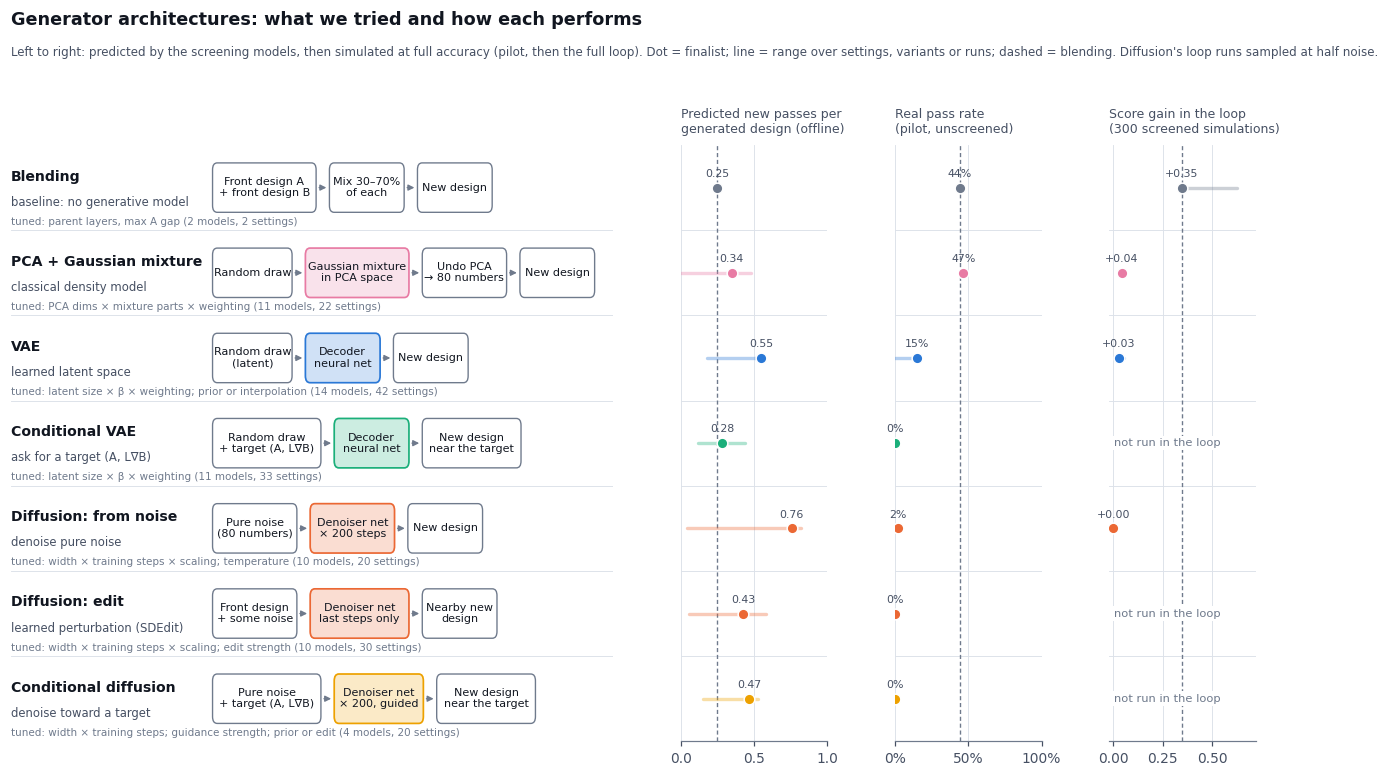

In [3]:
ROWS = [  # (key, family, strategies, title, how it makes a design, schematic boxes)
    ("blend", "blend", None, "Blending", "baseline: no generative model",
     [("Front design A\n+ front design B", "in"), ("Mix 30–70%\nof each", "op"), ("New design", "out")]),
    ("gmm", "gmm", None, "PCA + Gaussian mixture", "classical density model",
     [("Random draw", "in"), ("Gaussian mixture\nin PCA space", "model"), ("Undo PCA\n→ 80 numbers", "op"), ("New design", "out")]),
    ("vae", "vae", None, "VAE", "learned latent space",
     [("Random draw\n(latent)", "in"), ("Decoder\nneural net", "model"), ("New design", "out")]),
    ("cvae", "cvae", None, "Conditional VAE", "ask for a target (A, L∇B)",
     [("Random draw\n+ target (A, L∇B)", "in"), ("Decoder\nneural net", "model"), ("New design\nnear the target", "out")]),
    ("diff", "diff", ("prior",), "Diffusion: from noise", "denoise pure noise",
     [("Pure noise\n(80 numbers)", "in"), ("Denoiser net\n× 200 steps", "model"), ("New design", "out")]),
    ("diff_edit", "diff", ("edit",), "Diffusion: edit", "learned perturbation (SDEdit)",
     [("Front design\n+ some noise", "in"), ("Denoiser net\nlast steps only", "model"), ("Nearby new\ndesign", "out")]),
    ("cdiff", "cdiff", None, "Conditional diffusion", "denoise toward a target",
     [("Pure noise\n+ target (A, L∇B)", "in"), ("Denoiser net\n× 200, guided", "model"), ("New design\nnear the target", "out")]),
]
KNOBS = {"blend": "parent layers, max A gap", "gmm": "PCA dims × mixture parts × weighting",
         "vae": "latent size × β × weighting; prior or interpolation",
         "cvae": "latent size × β × weighting", "diff": "width × training steps × scaling; temperature",
         "diff_edit": "width × training steps × scaling; edit strength",
         "cdiff": "width × training steps; guidance strength; prior or edit"}
LOOP_ARMS = {"blend": ["w60_screen", "b60_screen"], "gmm": ["g60_gmm_k16_n16"], "vae": ["g60_vae_z32_b0.1"],
             "diff": ["g60_diff_w256_s3k_t0.5"]}   # first = the dot


def group(key, fam, strategies):
    rows = [r for r in study if r["family"] == fam and (strategies is None or r["strategy"] in strategies)]
    fins = [n for n, r in finalist_row.items() if r is not None and r in rows]
    if key == "blend":
        chosen = next((r for r in rows if r["config"].get("layers") == 3), rows[0] if rows else None)
    else:
        chosen = finalist_row[fins[0]] if fins else (max(rows, key=lambda r: r["metrics"]["top60"]) if rows else None)
    return rows, chosen, (fins[0] if fins else None)


def draw_chain(ax, y, items, color, x0=3.5):
    x = x0
    prev = None
    for text, kind in items:
        w = 0.083 * max(len(s) for s in text.split("\n")) + 0.42
        fc = {"model": color, "in": "white", "op": "white", "out": "white"}[kind]
        box = FancyBboxPatch((x, y - 0.27), w, 0.54, boxstyle="round,pad=0.02,rounding_size=0.08",
                             fc=fc, ec=color if kind == "model" else MUTED, lw=0.9,
                             alpha=1.0, zorder=2)
        ax.add_patch(box)
        if kind == "model":
            box.set_facecolor(color); box.set_alpha(0.22)
            ax.add_patch(FancyBboxPatch((x, y - 0.27), w, 0.54, boxstyle="round,pad=0.02,rounding_size=0.08",
                                        fc="none", ec=color, lw=1.1, zorder=3))
        ax.text(x + w / 2, y, text, ha="center", va="center", fontsize=7.3, color=INK, zorder=4,
                linespacing=1.15)
        if prev is not None:
            ax.add_patch(FancyArrowPatch((prev, y), (x - 0.02, y), arrowstyle="-|>", mutation_scale=8,
                                         color=MUTED, lw=0.9, zorder=1))
        prev = x + w + 0.02
        x += w + 0.27


n = len(ROWS)
fig = plt.figure(figsize=(14.6, 0.82 * n + 1.3))
gs = fig.add_gridspec(1, 4, width_ratios=[7.2, 1.75, 1.75, 1.75], wspace=0.26)
ax0 = fig.add_subplot(gs[0]); axes = [fig.add_subplot(gs[i]) for i in (1, 2, 3)]
ax0.set_xlim(0, 10.4); ax0.set_ylim(n - 0.5, -0.5); ax0.axis("off")
summary = {}
for i, (key, fam, strategies, title, idea, chain) in enumerate(ROWS):
    color = FAM[fam][0]
    rows, chosen, fin = group(key, fam, strategies)
    nconf = len({json.dumps(r["config"], sort_keys=True) for r in rows})
    ax0.text(0.0, i - 0.13, title, fontsize=9.2, fontweight="semibold", va="center", color=INK)
    ax0.text(0.0, i + 0.17, idea, fontsize=7.6, va="center", color=INK2)
    ax0.text(0.0, i + 0.40, f"tuned: {KNOBS[key]} ({nconf} models, {len(rows)} settings)",
             fontsize=6.8, va="center", color=MUTED)
    draw_chain(ax0, i, chain, color)
    if i < n - 1:
        for a in [ax0, *axes]:
            a.axhline(i + 0.5, color=RULE, lw=0.6, zorder=0)
    summary[key] = {"settings": len(rows), "models": nconf, "finalist": fin,
                    "chosen_label": chosen["label"] if chosen else None}
    def dot_range(ax, c, lo, hi, fmt):
        ax.plot([lo, hi], [i, i], color=color, lw=2.2, alpha=0.35, solid_capstyle="round", zorder=2)
        ax.plot(c, i, "o", color=color, ms=7, mec="white", mew=1, zorder=3)
        ax.annotate(fmt(c), (c, i), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=7.2, color=INK2)

    def absent(ax, text):
        ax.text(0.03, i, text, transform=ax.get_yaxis_transform(), va="center", color=MUTED, fontsize=7.5,
                bbox=dict(fc="white", ec="none", pad=1.5), zorder=5)

    # 1. predicted offline
    if rows:
        v = [r["metrics"]["yield"] for r in rows]
        dot_range(axes[0], chosen["metrics"]["yield"], min(v), max(v), lambda c: f"{c:.2f}")
        summary[key].update(predicted_yield=chosen["metrics"]["yield"], predicted_yield_range=[min(v), max(v)])
    else:
        absent(axes[0], "not run")
    # 2. real pass rate, pilot (unscreened)
    if key == "blend":
        real = [blend_real]
    else:
        real = [pilot[n]["pass_rate"] for n in pilot
                if G.FINALISTS[n][0]().kind == fam and (strategies is None or spec_of(n)[0] in strategies)]
    if real:
        c = pilot[fin]["pass_rate"] if fin in pilot else real[0]
        dot_range(axes[1], c, min(real), max(real), lambda c: f"{c:.0%}")
        summary[key].update(real_pass_rate=c, real_pass_rate_range=[min(real), max(real)])
    else:
        absent(axes[1], "not simulated")
    # 3. score gain in the loop, 300 screened simulations
    arms = LOOP_ARMS.get(key, [])
    gains = {a: [r["gain"][-1] for r in runs.get(a, [])] for a in arms}
    if gains and gains[arms[0]]:
        allg = [g for v in gains.values() for g in v]
        dot_range(axes[2], float(np.mean(gains[arms[0]])), min(allg), max(allg), lambda c: f"{c:+.2f}")
        summary[key].update(loop_score_gain=float(np.mean(gains[arms[0]])), loop_score_gain_range=[min(allg), max(allg)])
    else:
        absent(axes[2], "not run in the loop")
heads = ["Predicted new passes per\ngenerated design (offline)", "Real pass rate\n(pilot, unscreened)",
         "Score gain in the loop\n(300 screened simulations)"]
for ax, h in zip(axes, heads):
    ax.set_ylim(n - 0.5, -0.5); ax.set_yticks([]); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.set_title(h, fontsize=8.2, color=INK2, loc="left", pad=8)
    ax.set_xlim(left=0)
axes[0].set_xlim(0, 1.0)
axes[1].set_xlim(0, 1.0); axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[2].set_xlim(-0.02, 0.72)
for j, metric in enumerate(("predicted_yield", "real_pass_rate", "loop_score_gain")):
    if summary["blend"].get(metric) is not None:
        axes[j].axvline(summary["blend"][metric], color=MUTED, lw=0.9, ls=(0, (3, 2)), zorder=1)
fig.text(0.125, 1.035, "Generator architectures: what we tried and how each performs",
         fontweight="semibold", fontsize=11.5, ha="left")
fig.text(0.125, 0.995, "Left to right: predicted by the screening models, then simulated at full accuracy (pilot, "
         "then the full loop). Dot = finalist; line = range over settings, variants or runs; dashed = blending. "
         "Diffusion's loop runs sampled at half noise.", fontsize=7.8, color=INK2, ha="left")
fig.savefig(OUT / "architecture_trade.png")
plt.show()

## Novelty vs. validity

Every setting tried, one dot each. Copying training designs is easy, and copies tend to pass, but they aren't new. A useful generator sits up and to the right. The curves mark equal *yield* (new × predicted pass), the expected number of new passing designs per generated design.

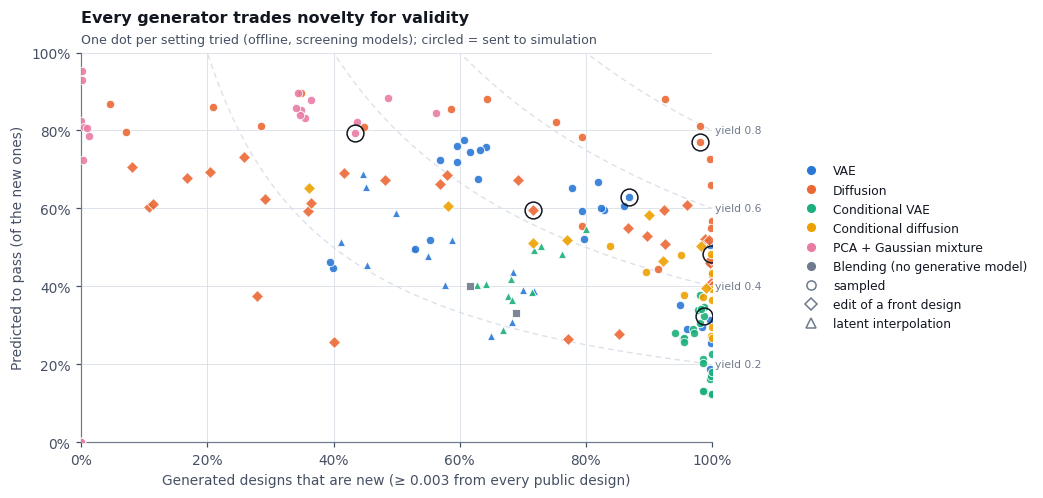

In [4]:
fig, ax = plt.subplots(figsize=(7.4, 4.6))
ax.grid(axis="x")
xs = np.linspace(0.02, 1, 200)
for y0 in (0.2, 0.4, 0.6, 0.8):
    ax.plot(xs, y0 / xs, color=RULE, lw=0.9, ls=(0, (4, 3)), zorder=0)
    ax.text(1.005, y0, f"yield {y0:.1f}", fontsize=7, color=MUTED, va="center")
for fam, (color, label) in FAM.items():
    rows = [r for r in study if r["family"] == fam]
    for r in rows:
        m = r["metrics"]
        ax.plot(m["novel"], m["valid"], MARK.get(r["strategy"], "o"), color=color, ms=5.5, mec="white",
                mew=0.6, alpha=0.9, zorder=3)
for name, r in finalist_row.items():
    if r is not None:
        ax.plot(r["metrics"]["novel"], r["metrics"]["valid"], "o", ms=11, mfc="none", mec=INK, mew=1.0, zorder=4)
ax.set_xlim(0, 1.0); ax.set_ylim(0, 1.0)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Generated designs that are new (≥ 0.003 from every public design)")
ax.set_ylabel("Predicted to pass (of the new ones)")
ax.set_title("Every generator trades novelty for validity", loc="left", fontweight="semibold", pad=20)
ax.text(0, 1.025, "One dot per setting tried (offline, screening models); circled = sent to simulation",
        transform=ax.transAxes, fontsize=8.3, color=INK2)
h = [Line2D([], [], ls="", marker="o", color=c, mec="white", ms=7, label=l) for c, l in FAM.values()]
h += [Line2D([], [], ls="", marker=MARK[k], color=MUTED, mfc="white", ms=6, label=l)
      for k, l in (("prior", "sampled"), ("edit", "edit of a front design"), ("interp", "latent interpolation"))]
ax.legend(handles=h, loc="center left", bbox_to_anchor=(1.12, 0.5), fontsize=8)
fig.savefig(OUT / "novelty_vs_validity.png")
plt.show()

## The main knob of each model

How often each model copies its training designs, as its main setting changes. Everything else is fixed, sampling at temperature 1 with no guidance.
- **Mixture and diffusion:** more capacity (mixture parts) or more training (diffusion steps) means more memorizing, so fewer new designs.
- **VAE:** β works the other way. A large β (strong pull toward the prior) collapses samples toward the average design, which sits close to existing ones. A small β gives new designs, but more of them fail (see the previous chart).

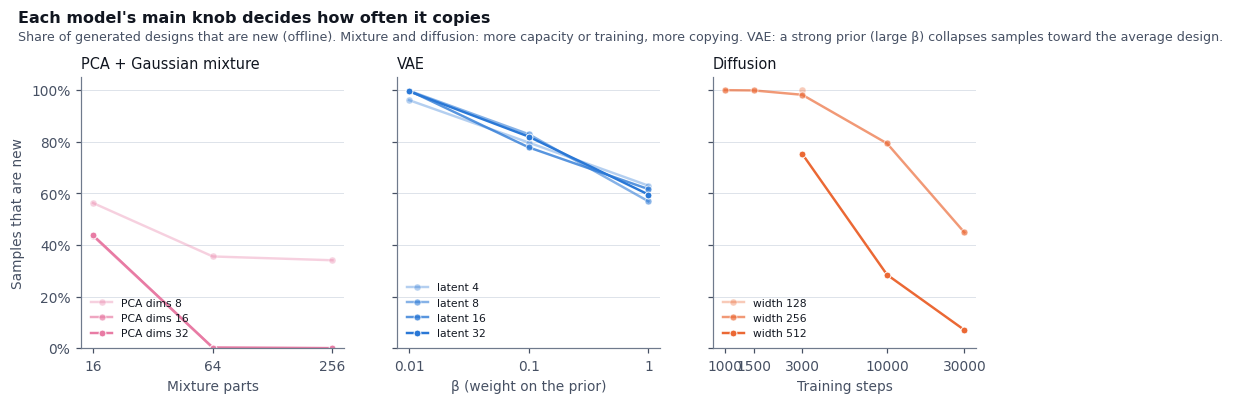

In [5]:
def series(fam, xkey, linekey, strategy="prior", temp=1.0, extra=None):
    rows = [r for r in study if r["family"] == fam and r["strategy"] == strategy and r["temp"] == temp
            and r["config"].get("weighting", "family") == "family" and r.get("guide", 0.0) == 0.0
            and all(r["config"].get(k) == v for k, v in (extra or {}).items())]
    out = {}
    for r in rows:
        out.setdefault(r["config"][linekey], []).append((r["config"][xkey], r["metrics"]["novel"], r["metrics"]["yield"]))
    return {k: sorted(v) for k, v in sorted(out.items())}


panels = [("gmm", "n", "k", "Mixture parts", "PCA dims", {}),
          ("vae", "beta", "latent", "β (weight on the prior)", "latent", {}),
          ("diff", "steps", "width", "Training steps", "width", {"scaling": "coef"})]
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.2), sharey=True)
for ax, (fam, xk, lk, xlabel, lname, extra) in zip(axs, panels):
    color = FAM[fam][0]
    s = series(fam, xk, lk, extra=extra)
    alphas = np.linspace(0.35, 1.0, len(s)) if len(s) > 1 else [1.0]
    ticks = set()
    for a, (lv, pts) in zip(alphas, s.items()):
        x, nov, _ = zip(*pts)
        ticks.update(x)
        ax.plot(x, nov, "-o", color=color, alpha=a, lw=1.6, ms=4.5, mec="white", mew=0.6, label=f"{lname} {lv}")
    ax.set_xscale("log"); ax.set_xlabel(xlabel)
    ax.set_xticks(sorted(ticks), [f"{v:g}" for v in sorted(ticks)]); ax.minorticks_off()
    ax.legend(fontsize=7, loc="lower left")
    ax.set_title(FAM[fam][1], loc="left", fontsize=9.5, color=INK)
    ax.set_ylim(0, 1.05)
axs[0].set_ylabel("Samples that are new")
axs[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle("Each model's main knob decides how often it copies", x=0.07, ha="left", y=1.07,
             fontweight="semibold", fontsize=10.5)
fig.text(0.07, 0.985, "Share of generated designs that are new (offline). Mixture and diffusion: more capacity or "
         "training, more copying. VAE: a strong prior (large β) collapses samples toward the average design.",
         fontsize=8.3, color=INK2)
fig.savefig(OUT / "memorization.png")
plt.show()

## Pilot: predicted vs. real

Unscreened designs per finalist, simulated at full accuracy: 60 each for the first five, then 40 each for three variants meant to stay closer to real designs. The variants were diffusion at half the sampling noise, diffusion editing front designs with 10% noise, and the VAE at temperature 0.3. Open circle: the screening models' predicted pass rate for those designs. Filled: the real pass rate. A big gap means the screening models misjudge that generator's designs. Blending's real rate (gray line) comes from its random-pick loop runs.

Nothing crashed. The printout below lists each finalist's failures by the constraint each one missed worst. QI dominates everywhere.

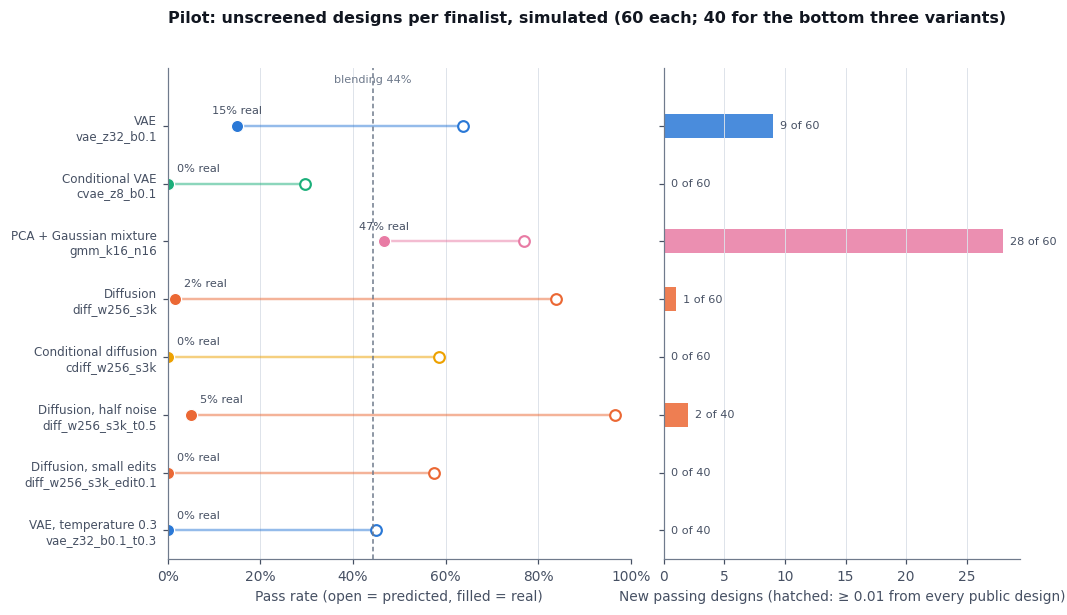

vae_z32_b0.1: 9/60 passed (15%; predicted 64%), 0 crashed
    failures by worst constraint: {'log10_qi_le_-3.5': 36, 'edge_mirror_le_0.25': 11, 'flux_compression_le_0.9': 3, 'edge_iota_ge_0.25': 1}
cvae_z8_b0.1: 0/60 passed (0%; predicted 30%), 0 crashed
    failures by worst constraint: {'log10_qi_le_-3.5': 43, 'edge_mirror_le_0.25': 17}
gmm_k16_n16: 28/60 passed (47%; predicted 77%), 0 crashed
    failures by worst constraint: {'log10_qi_le_-3.5': 27, 'vacuum_well_ge_0': 3, 'edge_mirror_le_0.25': 1, 'flux_compression_le_0.9': 1}
diff_w256_s3k: 1/60 passed (2%; predicted 84%), 0 crashed
    failures by worst constraint: {'log10_qi_le_-3.5': 40, 'edge_mirror_le_0.25': 14, 'flux_compression_le_0.9': 3, 'vacuum_well_ge_0': 1, 'edge_iota_ge_0.25': 1}
cdiff_w256_s3k: 0/60 passed (0%; predicted 59%), 0 crashed
    failures by worst constraint: {'log10_qi_le_-3.5': 35, 'edge_mirror_le_0.25': 23, 'vacuum_well_ge_0': 1, 'flux_compression_le_0.9': 1}
diff_w256_s3k_t0.5: 2/40 passed (5%; predict

In [6]:
names = [n for n in G.FINALISTS if n in pilot]
VARIANT = {"diff_w256_s3k_t0.5": "Diffusion, half noise", "diff_w256_s3k_edit0.1": "Diffusion, small edits",
           "vae_z32_b0.1_t0.3": "VAE, temperature 0.3"}   # second-round variants
if not names:
    print("pilot not simulated yet")
else:
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 0.55 * len(names) + 1.4), sharey=True,
                                 gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.08})
    for i, name in enumerate(names):
        p, fam = pilot[name], G.FINALISTS[name][0]().kind
        color = FAM[fam][0]
        ax.plot([p["predicted_pass_rate"], p["pass_rate"]], [i, i], color=color, lw=1.6, alpha=0.5)
        ax.plot(p["predicted_pass_rate"], i, "o", mfc="white", mec=color, mew=1.4, ms=7)
        ax.plot(p["pass_rate"], i, "o", color=color, mec="white", mew=0.8, ms=8)
        low = p["pass_rate"] < 0.08
        ax.annotate(f"{p['pass_rate']:.0%} real", (p["pass_rate"], i), xytext=(6 if low else 0, 8),
                    textcoords="offset points", ha="left" if low else "center", fontsize=7.4, color=INK2)
        bx.barh(i, p["passed"], height=0.42, color=color, alpha=0.85)
        bx.barh(i, p["strict_novel_passes"], height=0.42, color="none", ec=INK, lw=0.6, hatch="////")
        bx.text(p["passed"] + 0.6, i, f"{p['passed']} of {p['simulated']}", va="center", fontsize=7.4, color=INK2)
    if blend_real is not None:
        ax.axvline(blend_real, color=MUTED, lw=1, ls=(0, (3, 2)))
        ax.text(blend_real, -0.75, f"blending {blend_real:.0%}", fontsize=7.4, color=MUTED, ha="center")
    ax.set_yticks(range(len(names)), [f"{VARIANT.get(n, FAM[G.FINALISTS[n][0]().kind][1])}\n{n}" for n in names],
                  fontsize=7.8)
    ax.set_ylim(len(names) - 0.5, -1.0)
    ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="x"); ax.grid(axis="y", visible=False); bx.grid(axis="x"); bx.grid(axis="y", visible=False)
    ax.set_xlabel("Pass rate (open = predicted, filled = real)")
    bx.set_xlabel("New passing designs (hatched: ≥ 0.01 from every public design)")
    fig.suptitle("Pilot: unscreened designs per finalist, simulated (60 each; 40 for the bottom three variants)",
                 x=0.125, ha="left", y=0.97,
                 fontweight="semibold", fontsize=10.5)
    fig.savefig(OUT / "pilot.png")
    plt.show()
    for n in names:
        p = pilot[n]
        extra = (f"; targets: median |A − asked| {p['median_A_miss']:.2f}, median L∇B − asked {p['median_L_minus_asked']:+.2f}"
                 if "median_A_miss" in p else "")
        print(f"{n}: {p['passed']}/{p['simulated']} passed ({p['pass_rate']:.0%}; predicted "
              f"{p['predicted_pass_rate']:.0%}), {p['crashed']} crashed{extra}\n"
              f"    failures by worst constraint: {p['worst_constraint_of_failures']}")

## Loop runs: generators vs. blending at equal budgets

Each run: 5 rounds of 60 simulations (300) from the same shared start. Every round retrains the screening models on the run's own simulations so far and picks the 60 best-scoring new candidates. Line = mean of 3 runs, band = range. Random-pick blending (no ML at all) is the floor. The blending runs went on to 8 rounds; only their first 5 count here.

The right panel is the generators' story. The VAE's first screened round passed 2%, *worse* than its unscreened 15%, because the screen picked exactly the designs it misjudged most. Retraining on those failures lifted it to ~51%; diffusion never recovered. The table shows what that recovery cost: the passing designs the loop learned to trust are near-copies (median distance to the nearest public design just over the 0.003 threshold), and almost none are ≥ 0.01 away.

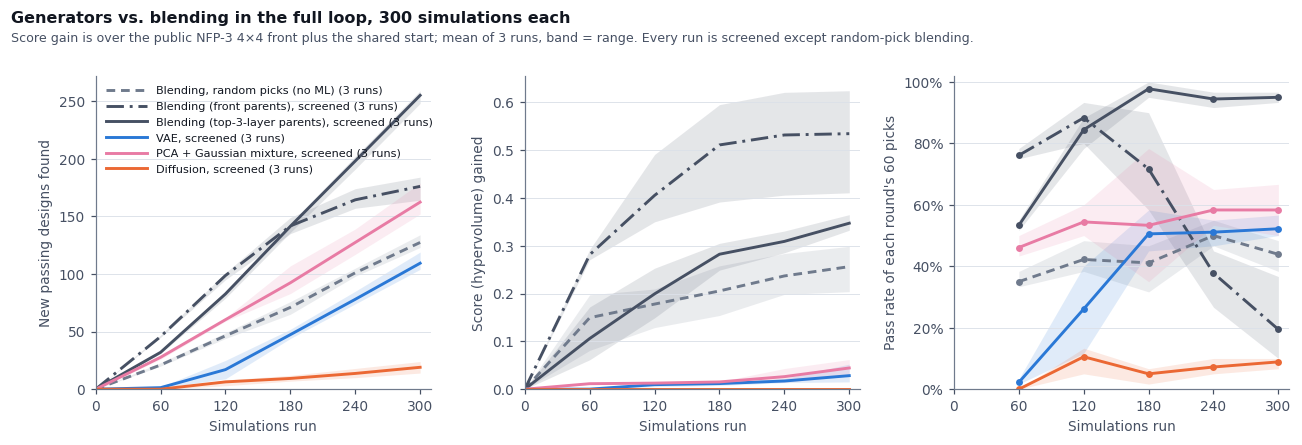

run                                        new passes ≥ 0.01 new median novelty         score gain
Blending, random picks (no ML)                    127       19.7         0.0066   +0.256 [+0.20, +0.30]
Blending (front parents), screened                176       66.3         0.0080   +0.534 [+0.41, +0.62]
Blending (top-3-layer parents), screened          255       10.3         0.0064   +0.347 [+0.33, +0.36]
VAE, screened                                     109        1.0         0.0039   +0.028 [+0.02, +0.05]
PCA + Gaussian mixture, screened                  162        0.0         0.0038   +0.044 [+0.03, +0.06]
Diffusion, screened                                19        0.0         0.0035   +0.000 [+0.00, +0.00]


In [7]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.7), gridspec_kw={"wspace": 0.28})
panels = ((axs[0], "novel", "New passing designs found"), (axs[1], "gain", "Score (hypervolume) gained"),
          (axs[2], "pass_rate", "Pass rate of each round's 60 picks"))
for ax, key, ylabel in panels:
    for arm, (seeds, fam, label, ls) in ARMS.items():
        if not runs[arm]:
            continue
        color = arm_color(arm)
        if key == "pass_rate":
            x = np.array(runs[arm][0]["sims"][1:])
            y = np.array([r["pass_rate"] for r in runs[arm]], float)
        else:
            x = np.array(runs[arm][0]["sims"])
            y = np.array([r[key] for r in runs[arm]], float)
        ax.fill_between(x, y.min(0), y.max(0), color=color, alpha=0.14, lw=0)
        ax.plot(x, y.mean(0), color=color, lw=1.9, ls=ls, marker="o" if key == "pass_rate" else None, ms=3.5,
                label=f"{label} ({len(runs[arm])} runs)")
    ax.set_xlabel("Simulations run"); ax.set_ylabel(ylabel); ax.set_xlim(0, 310)
    ax.set_xticks([0, 60, 120, 180, 240, 300])
axs[0].set_ylim(bottom=0); axs[1].set_ylim(bottom=0)
axs[2].set_ylim(0, 1.02); axs[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axs[0].legend(loc="upper left", fontsize=7.4, handlelength=3.6)
fig.suptitle("Generators vs. blending in the full loop, 300 simulations each", x=0.07, ha="left", y=1.04,
             fontweight="semibold", fontsize=10.5)
fig.text(0.07, 0.965, "Score gain is over the public NFP-3 4×4 front plus the shared start; mean of 3 runs, band = range. "
         "Every run is screened except random-pick blending.", fontsize=8.3, color=INK2)
fig.savefig(OUT / "loop_runs.png")
plt.show()

table = {}
print(f"{'run':42s} {'new passes':>10s} {'≥ 0.01 new':>10s} {'median novelty':>14s} {'score gain':>18s}")
for arm, (seeds, fam, label, ls) in ARMS.items():
    rs = runs[arm]
    if not rs:
        continue
    g = [r["gain"][-1] for r in rs]
    row = {"runs": len(rs), "sims": rs[0]["sims"][-1], "new_passes": float(np.mean([r["novel"][-1] for r in rs])),
           "strict_new_passes": float(np.mean([r["strict"] for r in rs])),
           "median_novelty": float(np.median(np.concatenate([r["novelty"] for r in rs]))),
           "score_gain_mean": float(np.mean(g)), "score_gain_range": [min(g), max(g)],
           "pass_rate_by_round": np.mean([r["pass_rate"] for r in rs], 0).round(3).tolist()}
    table[arm] = row
    print(f"{label:42s} {row['new_passes']:10.0f} {row['strict_new_passes']:10.1f} {row['median_novelty']:14.4f} "
          f"{row['score_gain_mean']:+8.3f} [{min(g):+.2f}, {max(g):+.2f}]")

## Buildability at each compactness level

The producibility reading of the same results. For each aspect ratio A (lower = more compact), the line shows the highest L∇B (higher = simpler coils) among passing designs at that A or lower. Black is the public NFP-3 4×4 designs; each other line adds one method's new passing designs from its first 300 simulations, pooled over its 3 runs. Where a line doesn't rise above black, that method found nothing more buildable at that compactness.

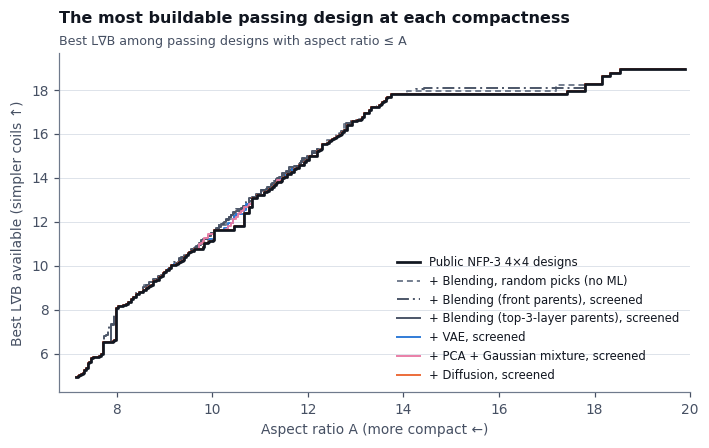

In [8]:
grid_A = np.linspace(6, 19.9, 400)


def best_L(A, L):
    y = G.front_height(grid_A, np.asarray(A, float), np.asarray(L, float))
    return np.where(y < 0, np.nan, y)          # no passing design at or below that A


fig, ax = plt.subplots(figsize=(7.4, 4.0))
base = best_L(pub["A"], pub["L"])
ax.plot(grid_A, base, color=INK, lw=1.8, drawstyle="steps-post", label="Public NFP-3 4×4 designs", zorder=4)
build = {}
for arm, (seeds, fam, label, ls) in ARMS.items():
    own = np.vstack([r["AL"] for r in runs[arm]]) if runs[arm] else np.empty((0, 2))
    if not len(own):
        continue
    y = best_L(np.r_[pub["A"], own[:, 0]], np.r_[pub["L"], own[:, 1]])
    ax.plot(grid_A, y, color=arm_color(arm), lw=1.3, ls=ls, drawstyle="steps-post", label=f"+ {label}", alpha=0.95)
    build[arm] = {f"A<={a}": float(y[np.searchsorted(grid_A, a) - 1]) for a in (8, 10, 12, 14, 16, 18)}
ax.set_xlabel("Aspect ratio A (more compact ←)"); ax.set_ylabel("Best L∇B available (simpler coils ↑)")
ax.set_title("The most buildable passing design at each compactness", loc="left", fontweight="semibold", pad=20)
ax.text(0, 1.025, "Best L∇B among passing designs with aspect ratio ≤ A", transform=ax.transAxes,
        fontsize=8.3, color=INK2)
ax.legend(loc="lower right", fontsize=7.6)
ax.set_xlim(6.8, 20)
fig.savefig(OUT / "buildability.png")
plt.show()

## Numbers

Everything above, for the report.

In [9]:
out = {"scope": "NFP 3, 4x4 Fourier modes; public front = public passing designs in that space",
       "metrics": "feasible = all 5 Benchmark 3 constraints within 1% (constellaration 0.2.6, high fidelity); "
                  "score = hypervolume over (-L_gradB, A), reference (1, 20); cost = simulations",
       "architectures": summary,
       "pilot": {k: {kk: vv for kk, vv in v.items() if kk not in ("A", "L")} for k, v in pilot.items()},
       "blending_real_pass_rate": blend_real,
       "loop_runs_300_sims": table,
       "loop_shared_start_score": base_pp,
       "buildability_best_L_at_A": {"public": {f"A<={a}": float(base[np.searchsorted(grid_A, a) - 1]) for a in (8, 10, 12, 14, 16, 18)},
                                    **build}}
(OUT / "trade_study.json").write_text(json.dumps(out, indent=1))
print(json.dumps(out["architectures"], indent=1))

{
 "blend": {
  "settings": 2,
  "models": 2,
  "finalist": null,
  "chosen_label": "blend layers 3 window 2.0",
  "predicted_yield": 0.24735758517928141,
  "predicted_yield_range": [
   0.2291766231179773,
   0.24735758517928141
  ],
  "real_pass_rate": 0.44375,
  "real_pass_rate_range": [
   0.44375,
   0.44375
  ],
  "loop_score_gain": 0.34703905514879807,
  "loop_score_gain_range": [
   0.33230300267271673,
   0.6240145769355934
  ]
 },
 "gmm": {
  "settings": 22,
  "models": 11,
  "finalist": "gmm_k16_n16",
  "chosen_label": "model gmm k 16 n 16 prior 1.0",
  "predicted_yield": 0.34484026627302367,
  "predicted_yield_range": [
   0.0,
   0.4747714178261593
  ],
  "real_pass_rate": 0.4666666666666667,
  "real_pass_rate_range": [
   0.4666666666666667,
   0.4666666666666667
  ],
  "loop_score_gain": 0.04435786562819999,
  "loop_score_gain_range": [
   0.027478798907736746,
   0.061981088660786554
  ]
 },
 "vae": {
  "settings": 42,
  "models": 14,
  "finalist": "vae_z32_b0.1",
  "ch